# Formative 2: Multimodal Data Preprocessing
## Part B: Image Pipeline and Facial Recognition Model (David)

Steps in this notebook:
1. Setup and mount Google Drive
2. Load and display images
3. Face detection, cropping and resizing
4. Image augmentation (5 per image)
5. Feature extraction (color histograms and MobileNetV2 embeddings) and `image_features.csv`
6. Facial recognition model (training and evaluation)
7. Prediction function with unauthorized-attempt handling
8. Command-line script `face_auth.py`

**Run the cells in order, top to bottom.** The feature-building cell rebuilds everything from scratch, so it is safe to rerun.

## 1. Setup

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
import os
import glob
import random
import cv2
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Shared team folder (read images from here). Add it to My Drive as a shortcut first.
SHARED_DIR = "/content/drive/MyDrive/Formative 2 ML_pipeline_Data_Collection"
IMAGE_DIR = f"{SHARED_DIR}/images"

# Your own output folder (write results here)
OUTPUT_DIR = "/content/drive/MyDrive/Formative2_outputs"
AUG_DIR = f"{OUTPUT_DIR}/augmented"
os.makedirs(AUG_DIR, exist_ok=True)

IMG_SIZE = (224, 224)
N_BINS = 16
random.seed(42)
np.random.seed(42)

print("Shared folder found:", os.path.exists(SHARED_DIR))

Shared folder found: True


## 2. Load and display images

In [4]:
def load_images(image_dir=IMAGE_DIR):
    records = []
    for member in sorted(os.listdir(image_dir)):
        member_path = os.path.join(image_dir, member)
        if not os.path.isdir(member_path):
            continue
        for path in sorted(glob.glob(os.path.join(member_path, "*"))):
            if not path.lower().endswith((".jpg", ".jpeg", ".png")):
                continue
            img = cv2.imread(path)
            if img is None:
                print(f"Could not read: {path}")
                continue
            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            expression = os.path.splitext(os.path.basename(path))[0].split("_")[-1].lower()
            expression = expression.replace("suprised", "surprised")  # fix filename typo
            records.append({"member": member.lower(), "expression": expression,
                            "path": path, "image": img})
    return records

records = load_images()
print(f"Loaded {len(records)} images")
for r in records:
    print(r["member"], "|", r["expression"], "|", r["image"].shape)

Loaded 9 images
david | neutral | (2576, 1932, 3)
david | smiling | (2576, 1932, 3)
david | surprised | (2576, 1932, 3)
faith | neutral | (3264, 1472, 3)
faith | smiling | (3264, 1472, 3)
faith | surprised | (3264, 1472, 3)
steven | neutral | (1920, 2560, 3)
steven | smiling | (1920, 2560, 3)
steven | surprised | (1920, 2560, 3)


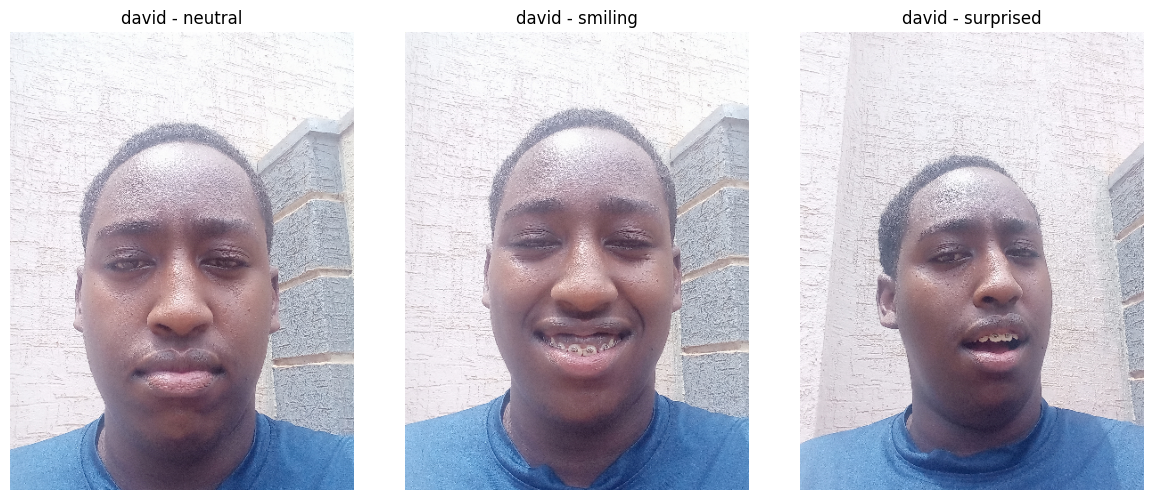

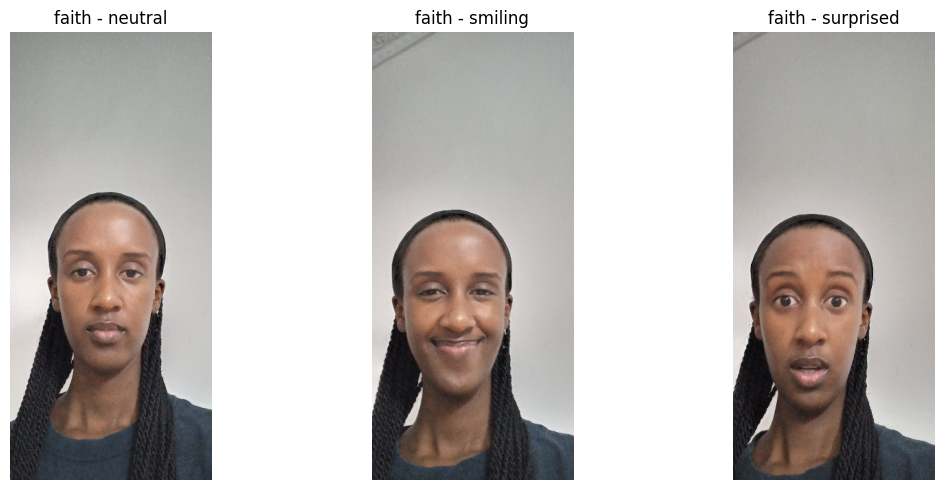

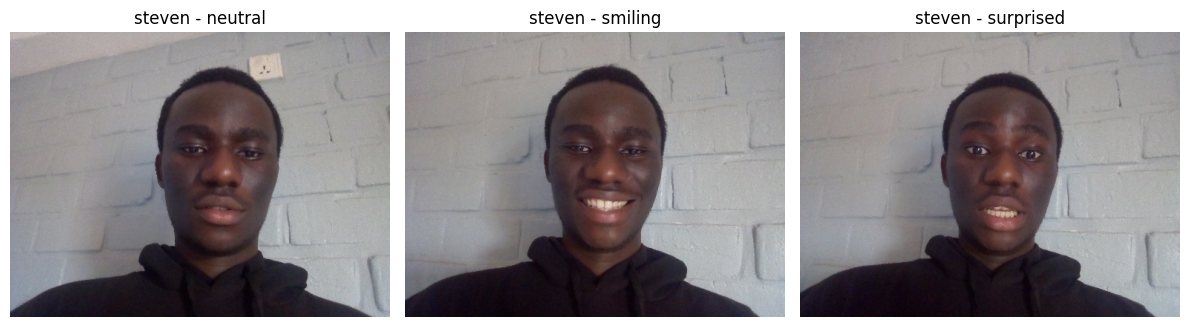

In [5]:
def display_member_images(records, member):
    imgs = [r for r in records if r["member"] == member]
    fig, axes = plt.subplots(1, len(imgs), figsize=(12, 5))
    for ax, r in zip(axes, imgs):
        small = cv2.resize(r["image"], (0, 0), fx=0.2, fy=0.2)  # shrink for display only
        ax.imshow(small)
        ax.set_title(f"{r['member']} - {r['expression']}")
        ax.axis("off")
    plt.tight_layout()
    plt.show()

for member in sorted({r["member"] for r in records}):
    display_member_images(records, member)

## 3. Face detection, cropping and resizing

The faces are detected with a cascade detector from scikit-image. Detections smaller than 25% of the image's short side are ignored (they were false matches such as a chin or an eye), and the detection closest to the image center is used. If no large face is found, a center crop is used instead.

david   neutral    large face detected: True
david   smiling    large face detected: True
david   surprised  large face detected: True
faith   neutral    large face detected: True
faith   smiling    large face detected: True
faith   surprised  large face detected: True
steven  neutral    large face detected: True
steven  smiling    large face detected: False
steven  surprised  large face detected: False


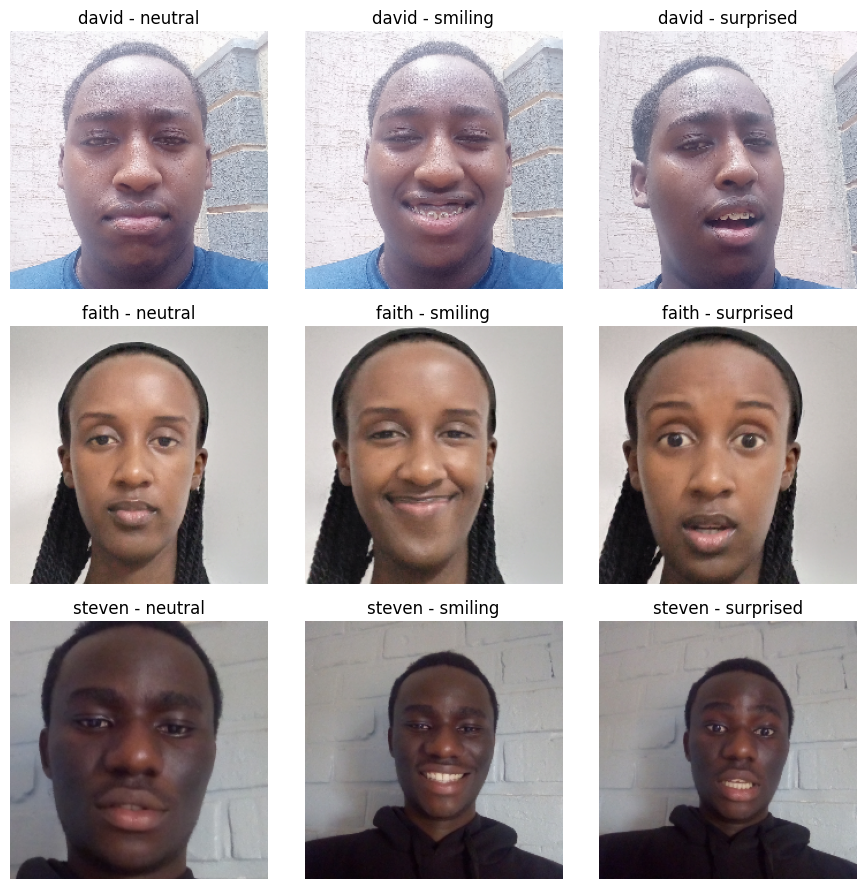

In [6]:
from skimage.data import lbp_frontal_face_cascade_filename
from skimage.feature import Cascade

detector = Cascade(lbp_frontal_face_cascade_filename())

def crop_face(img):
    """Detect faces, keep the large central one, crop with margin, resize to IMG_SIZE."""
    h, w = img.shape[:2]
    scale = 800 / max(h, w)
    small = cv2.resize(img, (int(w * scale), int(h * scale)))
    gray = cv2.cvtColor(small, cv2.COLOR_RGB2GRAY)
    sh, sw = small.shape[:2]

    faces = detector.detect_multi_scale(
        img=gray, scale_factor=1.1, step_ratio=1,
        min_size=(40, 40), max_size=(800, 800)
    )
    big = [f for f in faces if f["width"] >= 0.25 * min(sh, sw)]

    if len(big) > 0:
        def dist_to_center(f):
            cx, cy = f["c"] + f["width"] / 2, f["r"] + f["height"] / 2
            return (cx - sw / 2) ** 2 + (cy - sh / 2) ** 2
        f = min(big, key=dist_to_center)
        x, y, fw, fh = f["c"], f["r"], f["width"], f["height"]
        m = int(0.25 * max(fw, fh))
        x1, y1 = max(x - m, 0), max(y - m, 0)
        x2, y2 = min(x + fw + m, sw), min(y + fh + m, sh)
        crop, found = small[y1:y2, x1:x2], True
    else:
        s = min(sh, sw)
        y1, x1 = (sh - s) // 2, (sw - s) // 2
        crop, found = small[y1:y1 + s, x1:x1 + s], False

    return cv2.resize(crop, IMG_SIZE), found

processed = []
for r in records:
    face_img, found = crop_face(r["image"])
    processed.append({"member": r["member"], "expression": r["expression"], "image": face_img})
    print(f"{r['member']:7s} {r['expression']:10s} large face detected: {found}")

fig, axes = plt.subplots(3, 3, figsize=(9, 9))
for ax, p in zip(axes.flat, processed):
    ax.imshow(p["image"])
    ax.set_title(f"{p['member']} - {p['expression']}")
    ax.axis("off")
plt.tight_layout()
plt.show()

**Check the grid above.** Every crop should show a whole face. A `False` flag means the center-crop fallback was used, which is fine when the face is centered (this happened for two of Steven's photos).

## 4. Image augmentation (5 per image)

In [7]:
def rotate(img):
    angle = random.choice([-20, -10, 10, 20])
    h, w = img.shape[:2]
    M = cv2.getRotationMatrix2D((w / 2, h / 2), angle, 1.0)
    return cv2.warpAffine(img, M, (w, h), borderMode=cv2.BORDER_REFLECT)

def flip_horizontal(img):
    return cv2.flip(img, 1)

def to_grayscale(img):
    gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
    return cv2.cvtColor(gray, cv2.COLOR_GRAY2RGB)   # keep 3 channels

def adjust_brightness(img):
    factor = random.choice([0.6, 0.75, 1.3, 1.5])
    return np.clip(img.astype(np.float32) * factor, 0, 255).astype(np.uint8)

def add_noise(img, sigma=15):
    noise = np.random.normal(0, sigma, img.shape)
    return np.clip(img.astype(np.float32) + noise, 0, 255).astype(np.uint8)

AUGMENTATIONS = {
    "rotate": rotate,
    "flip": flip_horizontal,
    "grayscale": to_grayscale,
    "brightness": adjust_brightness,
    "noise": add_noise,
}

all_samples = []   # originals + augmented

for p in processed:
    member_dir = os.path.join(AUG_DIR, p["member"])
    os.makedirs(member_dir, exist_ok=True)

    all_samples.append({"member": p["member"], "expression": p["expression"],
                        "augmentation": "original", "image": p["image"]})

    for aug_name, aug_fn in AUGMENTATIONS.items():
        aug_img = aug_fn(p["image"])
        all_samples.append({"member": p["member"], "expression": p["expression"],
                            "augmentation": aug_name, "image": aug_img})
        fname = f"{p['member']}_{p['expression']}_{aug_name}.jpg"
        cv2.imwrite(os.path.join(member_dir, fname), cv2.cvtColor(aug_img, cv2.COLOR_RGB2BGR))

print(f"Total samples (originals + augmented): {len(all_samples)}")   # expect 54

Total samples (originals + augmented): 54


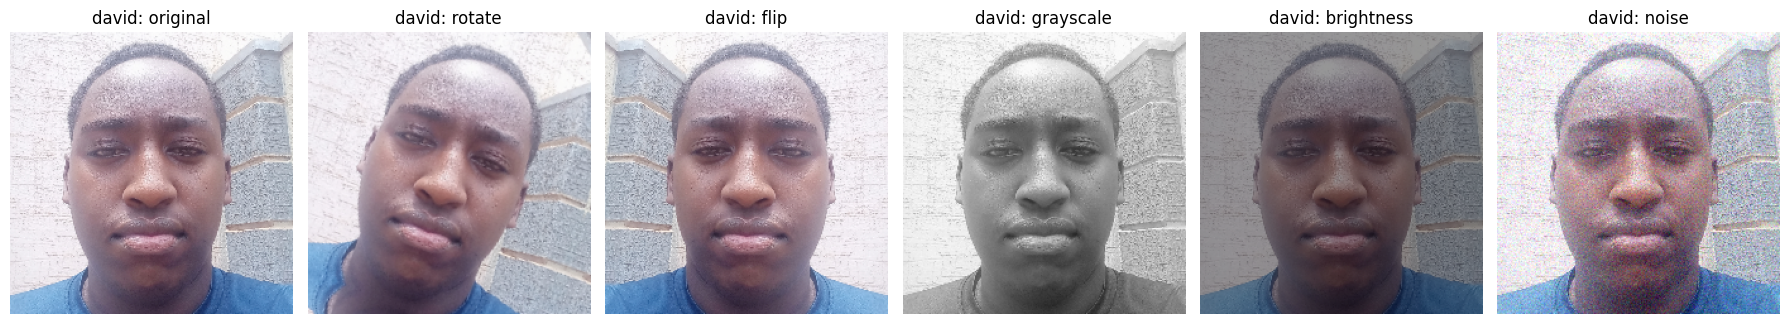

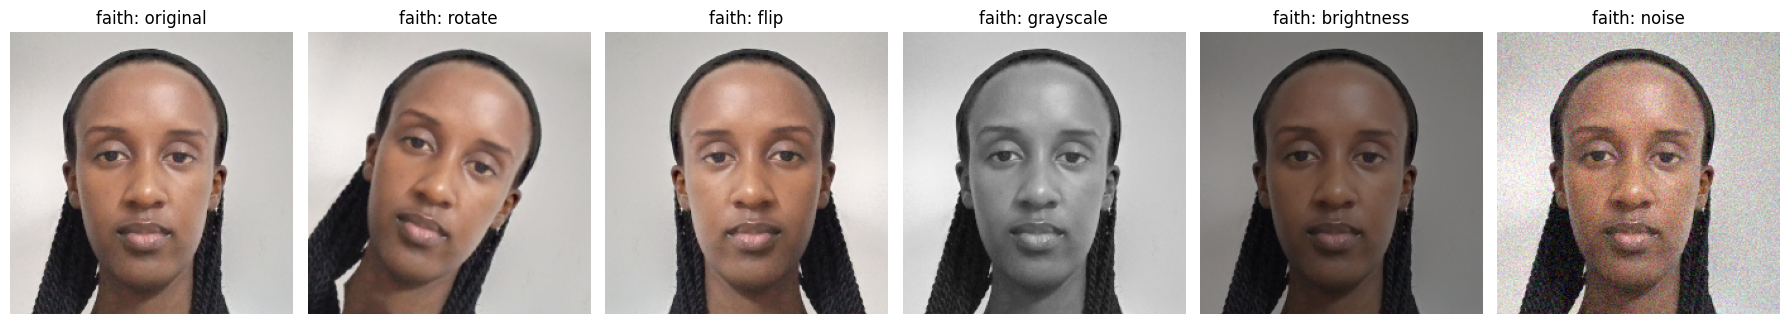

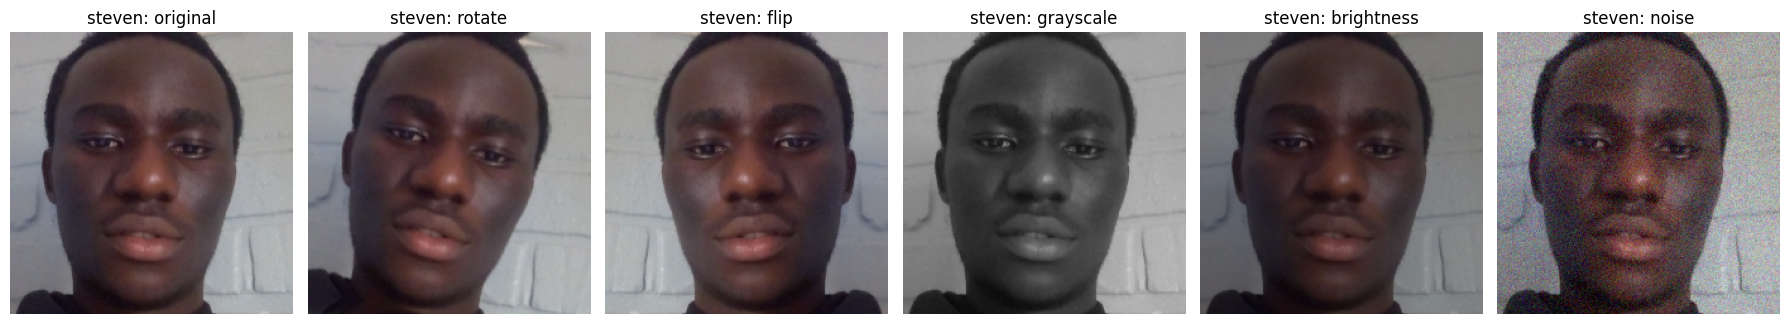

In [8]:
# Original and its 5 augmentations, one row per member (neutral expression)
for member in sorted({s["member"] for s in all_samples}):
    subset = [s for s in all_samples if s["member"] == member and s["expression"] == "neutral"]
    fig, axes = plt.subplots(1, len(subset), figsize=(18, 3.5))
    for ax, s in zip(axes, subset):
        ax.imshow(s["image"])
        ax.set_title(f"{member}: {s['augmentation']}")
        ax.axis("off")
    plt.tight_layout()
    plt.show()

## 5. Feature extraction and `image_features.csv`

Each sample gets 48 color-histogram features (16 bins x 3 channels) and a 1280-dimensional MobileNetV2 embedding. This cell rebuilds the feature table from scratch, so rerunning it does not duplicate columns.

In [9]:
import tensorflow as tf
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

def color_histogram(img, bins=N_BINS):
    feats = []
    for ch in range(3):  # R, G, B
        hist = cv2.calcHist([img], [ch], None, [bins], [0, 256]).flatten()
        feats.extend(hist / hist.sum())
    return feats

hist_cols = [f"{c}_hist_{i}" for c in ["r", "g", "b"] for i in range(N_BINS)]

rows = []
for s in all_samples:
    row = {"member": s["member"], "expression": s["expression"], "augmentation": s["augmentation"]}
    row.update(dict(zip(hist_cols, color_histogram(s["image"]))))
    rows.append(row)
hist_df = pd.DataFrame(rows)

embedder = MobileNetV2(weights="imagenet", include_top=False, pooling="avg", input_shape=(224, 224, 3))
batch = preprocess_input(np.array([s["image"] for s in all_samples]).astype("float32"))
embeddings = embedder.predict(batch, verbose=0)
emb_df = pd.DataFrame(embeddings, columns=[f"emb_{i}" for i in range(embeddings.shape[1])])

features_df = pd.concat([hist_df, emb_df], axis=1)

csv_path = f"{OUTPUT_DIR}/image_features.csv"
features_df.to_csv(csv_path, index=False)

check = pd.read_csv(csv_path)
print("Shape:", check.shape)                                # expect (54, 1331)
print("Duplicate columns:", check.columns.duplicated().sum())  # expect 0
print("Missing values:", check.isna().sum().sum())          # expect 0
print(check["member"].value_counts())

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Shape: (54, 1331)
Duplicate columns: 0
Missing values: 0
member
david     18
faith     18
steven    18
Name: count, dtype: int64


## 6. Facial recognition model

**Split:** all 6 versions of a photo are near-copies, so a random split would leak. We split by expression instead: neutral and smiling for training, surprised for testing (the model is tested on an expression it never saw).

In [10]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, f1_score, log_loss, confusion_matrix

df = pd.read_csv(f"{OUTPUT_DIR}/image_features.csv")
feature_cols = [c for c in df.columns if c.startswith(("r_hist", "g_hist", "b_hist", "emb_"))]

train = df[df["expression"] != "surprised"]
test = df[df["expression"] == "surprised"]

X_train, y_train = train[feature_cols].values, train["member"].values
X_test, y_test = test[feature_cols].values, test["member"].values
print("Train:", X_train.shape, "| Test:", X_test.shape)   # expect (36, 1328) | (18, 1328)

scaler = StandardScaler().fit(X_train)
X_train_s, X_test_s = scaler.transform(X_train), scaler.transform(X_test)

models = {
    "Logistic Regression": LogisticRegression(max_iter=2000, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42),
}

for name, model in models.items():
    model.fit(X_train_s, y_train)
    pred = model.predict(X_test_s)
    proba = model.predict_proba(X_test_s)
    print(f"\n=== {name} ===")
    print("Accuracy  :", round(accuracy_score(y_test, pred), 3))
    print("F1 (macro):", round(f1_score(y_test, pred, average="macro"), 3))
    print("Log loss  :", round(log_loss(y_test, proba, labels=model.classes_), 3))
    print("Confusion matrix (rows=true, cols=pred), order:", list(model.classes_))
    print(confusion_matrix(y_test, pred, labels=model.classes_))

joblib.dump(scaler, f"{OUTPUT_DIR}/face_scaler.pkl")
joblib.dump(models["Logistic Regression"], f"{OUTPUT_DIR}/face_model_logreg.pkl")
joblib.dump(models["Random Forest"], f"{OUTPUT_DIR}/face_model_rf.pkl")
print("\nModels saved.")

Train: (36, 1328) | Test: (18, 1328)

=== Logistic Regression ===
Accuracy  : 1.0
F1 (macro): 1.0
Log loss  : 0.006
Confusion matrix (rows=true, cols=pred), order: ['david', 'faith', 'steven']
[[6 0 0]
 [0 6 0]
 [0 0 6]]

=== Random Forest ===
Accuracy  : 1.0
F1 (macro): 1.0
Log loss  : 0.349
Confusion matrix (rows=true, cols=pred), order: ['david', 'faith', 'steven']
[[6 0 0]
 [0 6 0]
 [0 0 6]]

Models saved.


**Reading the results.** Both models are perfect on the test set, but the test set is tiny (3 people, 18 samples), so this shows the pipeline works, not that recognition is robust. Logistic Regression has a much lower log loss, meaning it is more confident when it is right, so it is used for the demo.

## 7. Prediction with unauthorized-attempt handling

A prediction is accepted only if (1) a face is detected and (2) the top class probability is at least `FACE_THRESHOLD`.

In [11]:
FACE_THRESHOLD = 0.60
final_model = joblib.load(f"{OUTPUT_DIR}/face_model_logreg.pkl")
final_scaler = joblib.load(f"{OUTPUT_DIR}/face_scaler.pkl")

def has_any_face(img):
    h, w = img.shape[:2]
    s = 800 / max(h, w)
    gray = cv2.cvtColor(cv2.resize(img, (int(w * s), int(h * s))), cv2.COLOR_RGB2GRAY)
    faces = detector.detect_multi_scale(img=gray, scale_factor=1.1, step_ratio=1,
                                        min_size=(40, 40), max_size=(800, 800))
    return len(faces) > 0

def extract_features(face_img):
    hist = color_histogram(face_img)
    x = preprocess_input(np.array([face_img]).astype("float32"))
    emb = embedder.predict(x, verbose=0)[0]
    return np.concatenate([hist, emb]).reshape(1, -1)

def predict_face(image_path):
    """Returns (name or None, confidence, message)."""
    img = cv2.imread(image_path)
    if img is None:
        return None, 0.0, "Could not read image."
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    if not has_any_face(img):
        return None, 0.0, "ACCESS DENIED: no face detected."

    face_img, _ = crop_face(img)
    feats = final_scaler.transform(extract_features(face_img))
    proba = final_model.predict_proba(feats)[0]
    best = proba.argmax()
    name, conf = final_model.classes_[best], float(proba[best])

    if conf < FACE_THRESHOLD:
        return None, conf, f"ACCESS DENIED: face not recognized (confidence {conf:.2f})."
    return name, conf, f"Face recognized: {name} (confidence {conf:.2f})."

# Authorized users. Note: only the 'surprised' photos were unseen during training.
for r in records:
    print(f"{r['member']:7s} {r['expression']:10s} ->", predict_face(r["path"])[2])

# Unauthorized attempt 1: an image with no face
noise = np.random.randint(0, 255, (400, 400, 3), dtype=np.uint8)
cv2.imwrite("/content/noise.jpg", noise)
print("noise image ->", predict_face("/content/noise.jpg")[2])

david   neutral    -> Face recognized: david (confidence 1.00).
david   smiling    -> Face recognized: david (confidence 1.00).
david   surprised  -> Face recognized: david (confidence 1.00).
faith   neutral    -> Face recognized: faith (confidence 1.00).
faith   smiling    -> Face recognized: faith (confidence 1.00).
faith   surprised  -> Face recognized: faith (confidence 1.00).
steven  neutral    -> Face recognized: steven (confidence 1.00).
steven  smiling    -> Face recognized: steven (confidence 1.00).
steven  surprised  -> Face recognized: steven (confidence 1.00).
noise image -> ACCESS DENIED: no face detected.


### Unauthorized attempt 2: a person who is not in the group

Upload a photo of someone outside the group to Colab (folder icon on the left, then upload) and set the path below.

In [12]:
stranger_path = "/content/stranger.jpg"   # change to your file's path

if os.path.exists(stranger_path):
    name, conf, msg = predict_face(stranger_path)
    print(msg)

    img = cv2.cvtColor(cv2.imread(stranger_path), cv2.COLOR_BGR2RGB)
    face_img, _ = crop_face(img)
    proba = final_model.predict_proba(final_scaler.transform(extract_features(face_img)))[0]
    print({k: round(float(v), 3) for k, v in zip(final_model.classes_, proba)})

    plt.imshow(face_img); plt.axis("off"); plt.show()
else:
    print("Upload a stranger photo and set stranger_path first.")

Upload a stranger photo and set stranger_path first.


## 8. Command-line script (`face_auth.py`)

In [13]:
%%writefile /content/drive/MyDrive/Formative2_outputs/face_auth.py
"""Face authentication step of the multimodal pipeline.

Usage:
    python face_auth.py --image path/to/photo.jpg
Exit code 0 = access granted, 1 = access denied.
"""
import argparse
import os
import sys

import cv2
import joblib
import numpy as np
from skimage.data import lbp_frontal_face_cascade_filename
from skimage.feature import Cascade
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

MODEL_DIR = os.path.dirname(os.path.abspath(__file__))
IMG_SIZE = (224, 224)
N_BINS = 16
FACE_THRESHOLD = 0.60

_detector = Cascade(lbp_frontal_face_cascade_filename())
_embedder = MobileNetV2(weights="imagenet", include_top=False, pooling="avg",
                        input_shape=(224, 224, 3))
_model = joblib.load(os.path.join(MODEL_DIR, "face_model_logreg.pkl"))
_scaler = joblib.load(os.path.join(MODEL_DIR, "face_scaler.pkl"))


def _detect(img):
    h, w = img.shape[:2]
    s = 800 / max(h, w)
    small = cv2.resize(img, (int(w * s), int(h * s)))
    gray = cv2.cvtColor(small, cv2.COLOR_RGB2GRAY)
    faces = _detector.detect_multi_scale(img=gray, scale_factor=1.1, step_ratio=1,
                                         min_size=(40, 40), max_size=(800, 800))
    return small, faces


def crop_face(img):
    small, faces = _detect(img)
    sh, sw = small.shape[:2]
    big = [f for f in faces if f["width"] >= 0.25 * min(sh, sw)]
    if big:
        def dist(f):
            cx, cy = f["c"] + f["width"] / 2, f["r"] + f["height"] / 2
            return (cx - sw / 2) ** 2 + (cy - sh / 2) ** 2
        f = min(big, key=dist)
        x, y, fw, fh = f["c"], f["r"], f["width"], f["height"]
        m = int(0.25 * max(fw, fh))
        crop = small[max(y - m, 0):min(y + fh + m, sh), max(x - m, 0):min(x + fw + m, sw)]
    else:
        s = min(sh, sw)
        y1, x1 = (sh - s) // 2, (sw - s) // 2
        crop = small[y1:y1 + s, x1:x1 + s]
    return cv2.resize(crop, IMG_SIZE)


def color_histogram(img):
    feats = []
    for ch in range(3):
        hist = cv2.calcHist([img], [ch], None, [N_BINS], [0, 256]).flatten()
        feats.extend(hist / hist.sum())
    return feats


def extract_features(face_img):
    x = preprocess_input(np.array([face_img]).astype("float32"))
    emb = _embedder.predict(x, verbose=0)[0]
    return np.concatenate([color_histogram(face_img), emb]).reshape(1, -1)


def predict_face(image_path):
    """Returns (name or None, confidence, message)."""
    img = cv2.imread(image_path)
    if img is None:
        return None, 0.0, "ACCESS DENIED: could not read image."
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    _, faces = _detect(img)
    if len(faces) == 0:
        return None, 0.0, "ACCESS DENIED: no face detected."

    feats = _scaler.transform(extract_features(crop_face(img)))
    proba = _model.predict_proba(feats)[0]
    best = proba.argmax()
    name, conf = _model.classes_[best], float(proba[best])
    if conf < FACE_THRESHOLD:
        return None, conf, f"ACCESS DENIED: face not recognized (confidence {conf:.2f})."
    return name, conf, f"Face recognized: {name} (confidence {conf:.2f})."


if __name__ == "__main__":
    parser = argparse.ArgumentParser(description="Face authentication")
    parser.add_argument("--image", required=True, help="path to a face image")
    args = parser.parse_args()
    name, conf, msg = predict_face(args.image)
    print(msg)
    sys.exit(0 if name else 1)

Overwriting /content/drive/MyDrive/Formative2_outputs/face_auth.py


In [19]:
# Test the script from the command line: an authorized user
!python /content/drive/MyDrive/Formative2_outputs/face_auth.py --image "/content/drive/MyDrive/Formative 2 ML_pipeline_Data_Collection/images/David/david_suprised.jpg"

I0000 00:00:1794384613.930000    6768 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1794384615.804976    6768 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
E0000 00:00:1794384617.178430    6768 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)
Face recognized: david (confidence 1.00).


In [21]:
# Test the script from the command line: the unauthorized stranger photo
!python /content/drive/MyDrive/Formative2_outputs/face_auth.py --image /content/drive/MyDrive/Formative2_outputs/stranger.jpg

I0000 00:00:1794384819.267463    7628 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1794384821.984734    7628 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
E0000 00:00:1794384823.352065    7628 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)
ACCESS DENIED: face not recognized (confidence 0.41).


In [16]:
import os
OUTPUT_DIR = "/content/drive/MyDrive/Formative2_outputs"
for f in ["face_model_logreg.pkl", "face_model_rf.pkl", "face_scaler.pkl", "image_features.csv", "face_auth.py"]:
    p = os.path.join(OUTPUT_DIR, f)
    print(f"{f:25s}", "OK" if os.path.exists(p) else "MISSING", f"({os.path.getsize(p)//1024} KB)" if os.path.exists(p) else "")

face_model_logreg.pkl     OK (32 KB)
face_model_rf.pkl         OK (177 KB)
face_scaler.pkl           OK (31 KB)
image_features.csv        OK (668 KB)
face_auth.py              OK (3 KB)


In [17]:
from google.colab import files
OUTPUT_DIR = "/content/drive/MyDrive/Formative2_outputs"
for f in ["face_model_logreg.pkl", "face_scaler.pkl", "face_auth.py", "image_features.csv"]:
    files.download(f"{OUTPUT_DIR}/{f}")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>